# Facial recognition

Photographs of four members are aligned, augmented, and converted to embeddings with EdgeFace-XXS (George, Ecabert, Shahreza, Kotwal, and Marcel, 2024). The weights are released under CC BY-NC-SA 4.0. A logistic regression then names the member from the embedding. A separate check compares a captured photograph with the stored embedding of the member who claims the transaction.


## Photographs

Each member is represented by three expressions: neutral, smile, and surprised. The files are named `{member}_{expression}.jpg`.


12 photographs, 4 members, 3 expressions


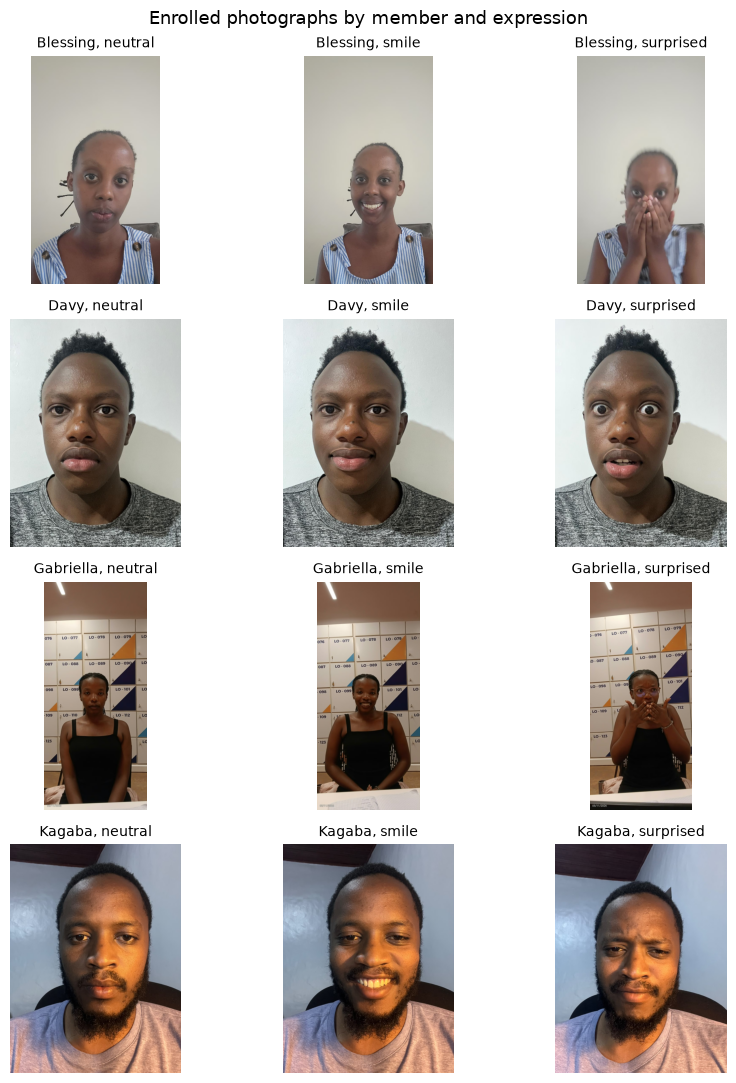

In [3]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageOps

warnings.filterwarnings("ignore", category=SyntaxWarning)


def project_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "facial_recognition_model" / "images").is_dir():
            return candidate
    raise FileNotFoundError("facial_recognition_model/images not found from " + str(here))


ROOT = project_root()
FACE = ROOT / "facial_recognition_model"
IMAGES = FACE / "images"
AUG = IMAGES / "augmented"
MEMBERS = ["blessing", "davy", "gabriella", "kagaba"]
EXPRESSIONS = ["neutral", "smile", "surprised"]

fig, axes = plt.subplots(len(MEMBERS), len(EXPRESSIONS), figsize=(9, 11))
for i, member in enumerate(MEMBERS):
    for j, expression in enumerate(EXPRESSIONS):
        image = Image.open(IMAGES / f"{member}_{expression}.jpg")
        axes[i, j].imshow(image)
        axes[i, j].set_title(f"{member.title()}, {expression}", fontsize=10)
        axes[i, j].axis("off")
fig.suptitle("Enrolled photographs by member and expression", fontsize=13)
fig.tight_layout()
plt.show()
print(f"{len(MEMBERS) * len(EXPRESSIONS)} photographs, {len(MEMBERS)} members, {len(EXPRESSIONS)} expressions")


## Alignment and embeddings

EdgeFace-XXS expects a 112 by 112 aligned face. The detector supplied with the model is MTCNN. It is created on CPU, because we are using a machine that has no CUDA device. The aligned face is scaled to the range expected by the network, with mean and standard deviation 0.5 on each channel. The network returns a 512-dimensional embedding.

Two further copies are made of every photograph: a horizontal flip and a brighter exposure. Those copies are aligned in the same way.


In [5]:
import torch
from torchvision import transforms

model = torch.hub.load(
    "otroshi/edgeface",
    "edgeface_xxs",
    source="github",
    pretrained=True,
    trust_repo=True,
)
model.eval()

repo = Path(torch.hub.get_dir()) / "otroshi_edgeface_main"
sys.path.insert(0, str(repo))
from face_alignment.mtcnn import MTCNN

detector = MTCNN(device="cpu", crop_size=(112, 112))
preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])


def align_face(image: Image.Image, source: str) -> Image.Image:
    _boxes, faces = detector.align_multi(image.convert("RGB"), limit=1)
    if not faces:
        raise RuntimeError(f"No face detected in {source}")
    return faces[0]


def embed(aligned: Image.Image) -> np.ndarray:
    tensor = preprocess(aligned).unsqueeze(0)
    with torch.no_grad():
        vector = model(tensor).squeeze(0).cpu().numpy()
    return vector.astype(np.float64)


AUG.mkdir(parents=True, exist_ok=True)
BRIGHTNESS = 1.4
records = []
example = {}

for member in MEMBERS:
    for expression in EXPRESSIONS:
        original_path = IMAGES / f"{member}_{expression}.jpg"
        original = Image.open(original_path).convert("RGB")
        variants = {
            "original": (original, original_path),
            "flip": (ImageOps.mirror(original), AUG / f"{member}_{expression}_flip.jpg"),
            "brightness": (
                ImageEnhance.Brightness(original).enhance(BRIGHTNESS),
                AUG / f"{member}_{expression}_brightness.jpg",
            ),
        }
        for name, (image, path) in variants.items():
            if name != "original":
                image.save(path, format="JPEG", quality=95)
            aligned = align_face(image, str(path.relative_to(FACE)))
            vector = embed(aligned)
            if member == "davy" and expression == "neutral":
                example[name] = image
                if name == "original":
                    example["aligned"] = aligned
            records.append({
                "member": member,
                "expression": expression,
                "augmentation": name,
                "source_file": str(path.relative_to(FACE)),
                "aligned": aligned,
                "embedding": vector,
            })

print(f"rows: {len(records)}")
print(f"embedding width: {records[0]['embedding'].shape[0]}")
print(f"augmented files: {len(list(AUG.glob('*.jpg')))}")


rows: 36
embedding width: 512
augmented files: 24


## Feature table

Each row is one photograph: the original, the flip, or the brighter copy. `member`, `expression`, and `augmentation` identify it, and `source_file` is the path of that file. `hist_r_*`, `hist_g_*`, and `hist_b_*` are 16-bin colour histograms of the aligned face, each channel scaled to sum to 1. `emb_0` through `emb_511` are the EdgeFace embedding of that same aligned face.


saved image_features.csv: 36 rows, 564 columns
missing values: 0
augmentation
brightness    12
flip          12
original      12


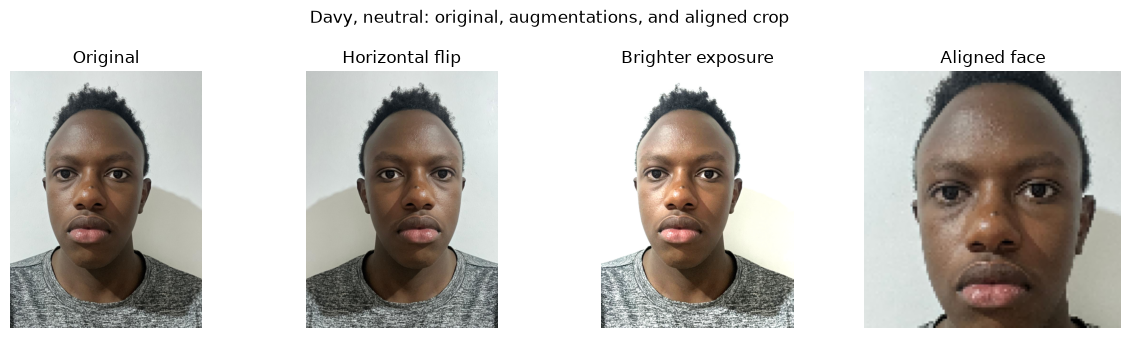

In [7]:
HIST_BINS = 16


def colour_histogram(aligned: Image.Image) -> np.ndarray:
    pixels = np.asarray(aligned, dtype=np.float64)
    channels = []
    for channel in range(3):
        counts, _edges = np.histogram(pixels[:, :, channel], bins=HIST_BINS, range=(0, 255))
        total = counts.sum()
        channels.append(counts / total if total else counts)
    return np.concatenate(channels)


rows = []
for record in records:
    row = {
        "member": record["member"],
        "expression": record["expression"],
        "augmentation": record["augmentation"],
        "source_file": record["source_file"],
    }
    histogram = colour_histogram(record["aligned"])
    labels = (
        [f"hist_r_{i:02d}" for i in range(HIST_BINS)]
        + [f"hist_g_{i:02d}" for i in range(HIST_BINS)]
        + [f"hist_b_{i:02d}" for i in range(HIST_BINS)]
    )
    for label, value in zip(labels, histogram):
        row[label] = value
    for index, value in enumerate(record["embedding"]):
        row[f"emb_{index}"] = value
    rows.append(row)

features = pd.DataFrame(rows)
csv_path = FACE / "image_features.csv"
features.to_csv(csv_path, index=False)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
panels = [
    ("original", "Original"),
    ("flip", "Horizontal flip"),
    ("brightness", "Brighter exposure"),
    ("aligned", "Aligned face"),
]
for axis, (key, title) in zip(axes, panels):
    axis.imshow(example[key])
    axis.set_title(title)
    axis.axis("off")
fig.suptitle("Davy, neutral: original, augmentations, and aligned crop", fontsize=12)
fig.tight_layout()
plt.show()

print(f"saved {csv_path.name}: {features.shape[0]} rows, {features.shape[1]} columns")
print("missing values:", int(features.isna().sum().sum()))
print(features.groupby(["augmentation"]).size().to_string())


## Naming the member

The classifier reads only the 512 embedding columns. The colour histograms remain in the table as a description of the aligned face. Neutral and smile photographs, including their augmentations, are the fitting set. Every surprised photograph, including its flip and its brighter copy, is held out. A flipped copy of a surprised face is therefore not available while the classifier is fitted.

Accuracy, macro F1, and log loss are reported first on the four original surprised photographs, and then on all twelve held-out rows.


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

embedding_columns = [column for column in features.columns if column.startswith("emb_")]
train = features[features["expression"].isin(["neutral", "smile"])].copy()
held_out = features[features["expression"].eq("surprised")].copy()
held_out_original = held_out[held_out["augmentation"].eq("original")].copy()

classifier = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(C=0.1, max_iter=2000, random_state=42)),
])
classifier.fit(train[embedding_columns], train["member"])


def score_split(split: pd.DataFrame, title: str) -> None:
    probabilities = classifier.predict_proba(split[embedding_columns])
    predicted = classifier.predict(split[embedding_columns])
    print(title)
    print(f"  photographs: {len(split)}")
    print(f"  accuracy: {accuracy_score(split['member'], predicted):.3f}")
    print(f"  macro F1: {f1_score(split['member'], predicted, average='macro'):.3f}")
    print(f"  log loss: {log_loss(split['member'], probabilities, labels=list(classifier.classes_)):.3f}")
    named = split[["member", "expression", "augmentation"]].copy()
    named["predicted"] = predicted
    print(named.to_string(index=False))
    print()


print(f"fitting rows: {len(train)}")
print("classes:", list(classifier.classes_))
print()
score_split(held_out_original, "Held-out originals")
score_split(held_out, "Held-out originals and their augmentations")


fitting rows: 24
classes: ['blessing', 'davy', 'gabriella', 'kagaba']

Held-out originals
  photographs: 4
  accuracy: 1.000
  macro F1: 1.000
  log loss: 0.079
   member expression augmentation predicted
 blessing  surprised     original  blessing
     davy  surprised     original      davy
gabriella  surprised     original gabriella
   kagaba  surprised     original    kagaba

Held-out originals and their augmentations
  photographs: 12
  accuracy: 1.000
  macro F1: 1.000
  log loss: 0.072
   member expression augmentation predicted
 blessing  surprised     original  blessing
 blessing  surprised         flip  blessing
 blessing  surprised   brightness  blessing
     davy  surprised     original      davy
     davy  surprised         flip      davy
     davy  surprised   brightness      davy
gabriella  surprised     original gabriella
gabriella  surprised         flip gabriella
gabriella  surprised   brightness gabriella
   kagaba  surprised     original    kagaba
   kagaba  surprise

On the four original surprised photographs, accuracy is 1.000, macro F1 is 1.000, and log loss is 0.079. The same names are returned for the flips and the brighter copies. Across all twelve held-out rows, accuracy and macro F1 remain 1.000 and log loss is 0.072.


## Accept or reject a claim

The stored vector of a member is the average embedding of that member's original neutral and smile photographs. A captured photograph is accepted when its cosine similarity to the claimed member's stored vector is at least the cutoff, and rejected otherwise.

The cutoff is chosen from the neutral and smile photographs alone. For each of those photographs the genuine score is the similarity to the member's other original photograph, and the impostor scores are the similarities to the stored vectors of the other members. The cutoff is the value that best separates those two groups. The surprised photographs are scored only after the cutoff is fixed.


genuine scores on enrollment pairs: [0.819, 0.918, 0.859, 0.836]
impostor scores: min 0.022, max 0.250
cutoff: 0.534
enrollment separation at that cutoff: 1.000

Claim Blessing    photo images/blessing_surprised.jpg  similarity 0.542  accepted
Claim Davy        photo images/davy_surprised.jpg     similarity 0.876  accepted
Claim Gabriella   photo images/gabriella_surprised.jpg  similarity 0.633  accepted
Claim Kagaba      photo images/kagaba_surprised.jpg   similarity 0.837  accepted

Claim Davy        photo images/blessing_surprised.jpg  similarity 0.193  rejected
Claim Gabriella   photo images/blessing_surprised.jpg  similarity 0.016  rejected
Claim Kagaba      photo images/blessing_surprised.jpg  similarity 0.174  rejected
Claim Blessing    photo images/davy_surprised.jpg     similarity 0.268  rejected
Claim Gabriella   photo images/davy_surprised.jpg     similarity 0.087  rejected
Claim Kagaba      photo images/davy_surprised.jpg     similarity 0.106  rejected
Claim Blessing    pho

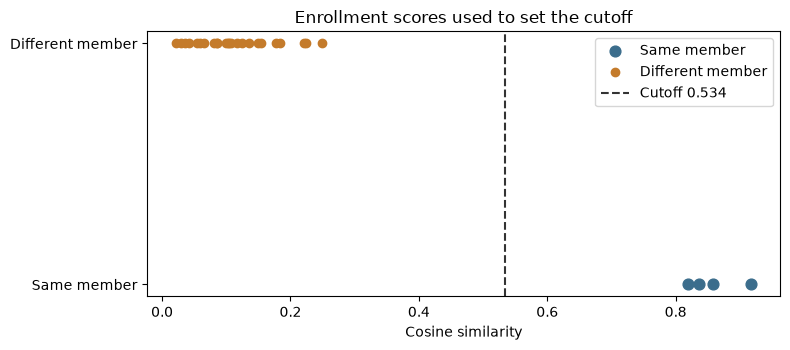

In [12]:
def unit(vector: np.ndarray) -> np.ndarray:
    vector = np.asarray(vector, dtype=np.float64)
    return vector / np.linalg.norm(vector)


def cosine(left: np.ndarray, right: np.ndarray) -> float:
    return float(np.dot(unit(left), unit(right)))


enrollment = features[
    features["expression"].isin(["neutral", "smile"]) & features["augmentation"].eq("original")
].copy()
stored = {
    member: unit(group[embedding_columns].mean().to_numpy())
    for member, group in enrollment.groupby("member")
}

genuine_scores = []
impostor_scores = []
for member, group in enrollment.groupby("member"):
    vectors = list(group[embedding_columns].to_numpy())
    genuine_scores.append(cosine(vectors[0], vectors[1]))
    for vector in vectors:
        for other, centroid in stored.items():
            if other != member:
                impostor_scores.append(cosine(vector, centroid))

candidates = np.sort(np.unique(np.concatenate([genuine_scores, impostor_scores])))
midpoints = (candidates[:-1] + candidates[1:]) / 2.0
best_cutoff, best_balance = midpoints[0], -1.0
for cutoff in midpoints:
    genuine_hit = np.mean(np.asarray(genuine_scores) >= cutoff)
    impostor_hit = np.mean(np.asarray(impostor_scores) < cutoff)
    balance = 0.5 * (genuine_hit + impostor_hit)
    if balance > best_balance:
        best_cutoff, best_balance = float(cutoff), float(balance)

surprised = features[
    features["expression"].eq("surprised") & features["augmentation"].eq("original")
].copy()


def claim_similarity(row: pd.Series, claimed: str) -> float:
    vector = row[embedding_columns].to_numpy()
    return cosine(vector, stored[claimed])


print(f"genuine scores on enrollment pairs: {np.round(genuine_scores, 3).tolist()}")
print(f"impostor scores: min {min(impostor_scores):.3f}, max {max(impostor_scores):.3f}")
print(f"cutoff: {best_cutoff:.3f}")
print(f"enrollment separation at that cutoff: {best_balance:.3f}")
print()

authorized_correct = 0
for _, row in surprised.iterrows():
    score = claim_similarity(row, row["member"])
    accepted = score >= best_cutoff
    authorized_correct += int(accepted)
    decision = "accepted" if accepted else "rejected"
    print(f"Claim {row['member'].title():10s}  photo {row['source_file']:28s}  similarity {score:.3f}  {decision}")

unauthorized_correct = 0
unauthorized_total = 0
print()
for _, row in surprised.iterrows():
    for claimed in MEMBERS:
        if claimed == row["member"]:
            continue
        unauthorized_total += 1
        score = claim_similarity(row, claimed)
        rejected = score < best_cutoff
        unauthorized_correct += int(rejected)
        decision = "rejected" if rejected else "accepted"
        print(
            f"Claim {claimed.title():10s}  photo {row['source_file']:28s}  "
            f"similarity {score:.3f}  {decision}"
        )

print()
print(f"authorized claims correct: {authorized_correct}/{len(surprised)}")
print(f"unauthorized claims rejected: {unauthorized_correct}/{unauthorized_total}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(genuine_scores, np.zeros(len(genuine_scores)), s=60, color="#3B6D8C", label="Same member", zorder=3)
ax.scatter(impostor_scores, np.ones(len(impostor_scores)), s=36, color="#C47B2B", label="Different member", zorder=3)
ax.axvline(best_cutoff, color="#333333", linestyle="--", label=f"Cutoff {best_cutoff:.3f}")
ax.set_yticks([0, 1], ["Same member", "Different member"])
ax.set_xlabel("Cosine similarity")
ax.set_title("Enrollment scores used to set the cutoff")
ax.legend(loc="best")
fig.tight_layout()
plt.show()


Same-member enrollment scores lie between 0.819 and 0.918. Scores against a different member's stored vector lie between 0.022 and 0.250. The cutoff that separates those groups is 0.534. Each surprised photograph is accepted under the member's own name: Blessing 0.542, Gabriella 0.633, Kagaba 0.837, and Davy 0.876. Blessing's score is the nearest to the cutoff. All 12 claims made under another member's name fall below the cutoff and are rejected; the highest of them is 0.268.


## Summary

The folder holds twelve photographs: Blessing, Davy, Gabriella, and Kagaba, each with a neutral expression, a smile, and a surprised expression. A horizontal flip and a brighter exposure of every photograph are stored under `images/augmented/`. `image_features.csv` has 36 rows and 564 columns, with no missing values. The columns are the member, the expression, the augmentation, the file path, 16-bin colour histograms of the aligned face, and the 512 EdgeFace-XXS embedding.

Fitted on the neutral and smile embeddings, the logistic regression names every held-out surprised photograph correctly. On the four originals, accuracy is 1.000, macro F1 is 1.000, and log loss is 0.079.

During the transaction check a photograph is accepted when its cosine similarity to the stored embedding of the claimed member is at least 0.534, the cutoff fixed from the neutral and smile photographs. All four surprised photographs are accepted under their own names, and all 12 claims under another member's name are rejected. Blessing's own-name score, 0.542, is the closest to the cutoff.
